# Data Cleaning and Data Storytelling in Python
**Project:** an online-store orders file that arrives in a typical messy state, and what it takes to turn it into numbers you can trust.

**What you will practise**

| Skill | Where |
|---|---|
| Finding every kind of "missing" (`N/A`, `-`, `?`, blank) | Steps 2 and 3 |
| Standardising inconsistent text (`hyd`, `HYDERABAD `, `Hyderabad`) | Step 4 |
| Fixing data types: mixed date formats, prices stored as `₹1,299` | Step 5 |
| Finding and removing exact and near duplicates | Step 6 |
| Detecting outliers (IQR, z-score, domain rules) and deciding what to do | Step 7 |
| Choosing a missing-value strategy per column, not one rule for all | Step 8 |
| Proving the data is clean with validation checks | Step 9 |
| Showing the before and after, then telling the story with charts | Steps 10 and 11 |
| Delivering an HTML report for people who will never open this notebook | Step 12 |

**Libraries:** pandas and NumPy for the cleaning, Matplotlib and Seaborn for the charts.

**How the notebook is organised:** each step explains the problem, shows the evidence, fixes it, and writes one line to a *cleaning log*. The log becomes part of the final report, so anyone can see exactly what was changed and why.

In [1]:
from pathlib import Path
import base64, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Folders (works whether you start Jupyter in the project root or in notebook/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA, FIG, REPORT = ROOT / "data", ROOT / "figures", ROOT / "report"
for folder in (FIG, REPORT):
    folder.mkdir(exist_ok=True)

# One consistent look for every chart
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left"})
TEAL, AMBER, GREY = "#0f766e", "#b45309", "#94a3b8"
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 150)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

# A cleaning log: every fix gets one line, so the work is auditable
LOG = []
def log(step, issue, action, affected, unit="rows"):
    LOG.append({"step": step, "issue": issue, "action": action, "affected": int(affected), "unit": unit})

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150, facecolor="white")

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


## Step 1. Load the data without letting pandas guess
We read every column as **text** (`dtype=str`) and switch off pandas' automatic NA detection (`keep_default_na=False`).
That looks backwards, but it means nothing is silently converted, so we can *see* the mess before we decide how to treat it.

In [2]:
raw = pd.read_csv(DATA / "raw_orders.csv", dtype=str, keep_default_na=False)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head(8))

2,435 rows x 16 columns


,order_id,order_date,customer_id,customer_name,email,age,city,category,product,quantity,unit_price,discount_pct,payment_method,delivery_days,rating,status
0,ORD-21379,21-Jan-2026,C0161,Arjun Iyer,arjun.iyer161@example.com,None,CHENNAI,Beauty,Perfume,1,N/A,20,Debit Card,3,5,Delivered
1,ORD-21151,2025-11-23,C0204,Priya Gupta,priya.gupta204@example.com,29,Pune,Beauty,Hair Dryer,1,1620,25,Cash on Delivery,2,na,Delivered
2,ORD-20356,2025-05-07,C0443,Priya Das,priya.das443@example.com,37,Mumbai,Fashion,Backpack,1,1640,0,UPI,2,5,returned
3,ORD-22290,27-Sep-2026,C0882,Saanvi Gupta,saanvi.gupta882@example.com,?,Delhi,Home & Kitchen,Air Fryer,1,"₹6,505",20,debit card,5,None,Delivered
4,ORD-22273,2026-09-25,C0668,Ananya Singh,ananya.singh668@example.com,54,Delhi,Fashion,Backpack,1,1707,20,UPI,3,5,Delivered
5,ORD-21757,13-May-2026,C0364,Sneha Das,sneha.das364@example.com,48,na,Home & Kitchen,Cookware Set,3,"Rs. 4,896",15,Debit Card,6,5,Delivered
6,ORD-20237,2025-03-27,C0850,Aarav Joshi,aarav.joshi850@example.com,35,Hyderabad,Books,Cookbook,2,702,0,N/A,3,5,Delivered
7,ORD-21579,2026-03-28,C0626,Meera Patel,meera.patel626@example.com,38,Mumbai,Beauty,Face Serum,2,₹941,10,Credit Card,5,3,Delivered


## Step 2. Audit: measure the problems before fixing any
Good cleaning starts with a short list of *what is wrong and how much*. We check four things: placeholders for missing values, inconsistent text, duplicates, and impossible numbers.

In [3]:
# Every spelling of "missing" we can find in this file
NA_TOKENS = {"", "n/a", "na", "null", "-", "?", "none", "nan"}
def is_missing(s):
    return s.str.strip().str.lower().isin(NA_TOKENS)

audit = pd.DataFrame({"missing": {c: int(is_missing(raw[c]).sum()) for c in raw.columns},
                      "distinct_values": raw.nunique()})
audit["pct"] = (audit["missing"] / len(raw) * 100).round(1)
display(audit.sort_values("missing", ascending=False))

,missing,distinct_values,pct
rating,313,15,12.9
discount_pct,244,17,10.0
age,188,55,7.7
email,142,815,5.8
delivery_days,120,22,4.9
payment_method,96,35,3.9
customer_name,74,293,3.0
city,50,57,2.1
unit_price,36,2043,1.5
category,34,42,1.4


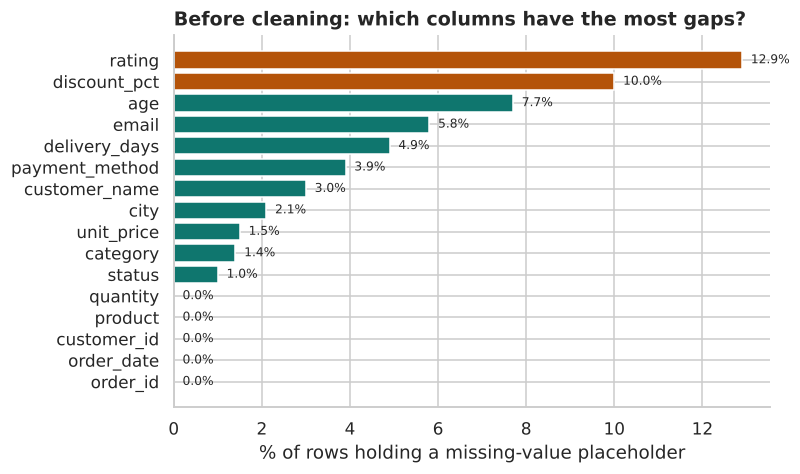

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.4))
s = audit["pct"].sort_values()
ax.barh(s.index, s.values, color=[AMBER if v >= 10 else TEAL for v in s.values])
for y, v in enumerate(s.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% of rows holding a missing-value placeholder")
ax.set_title("Before cleaning: which columns have the most gaps?")
save(fig, "01_missing_before.png"); plt.show()

In [5]:
# Inconsistent text: the same thing written many ways
for col in ["category", "payment_method", "status"]:
    print(f"{col:15s}", sorted(raw[col].unique()))
print(f"{'city':15s}", sorted(raw["city"].unique()))

# Duplicates
print()
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Order IDs appearing twice :", raw["order_id"].duplicated().sum())

category        ['', ' Beauty ', ' Books ', ' Electronics ', ' Fashion ', ' Home & Kitchen ', ' Sports ', '-', '?', 'BEAUTY', 'BOOKS', 'Beauty', 'Beauty  ', 'Beuty', 'Books', 'Books  ', 'ELECTRONICS', 'Electroncs', 'Electronics', 'Electronics  ', 'FASHION', 'Fashion', 'Fashion  ', 'Fasion', 'HOME & KITCHEN', 'Home & Kitchen', 'Home & Kitchen  ', 'Home and Kitchen', 'N/A', 'NULL', 'None', 'SPORTS', 'Sport', 'Sports', 'Sports  ', 'beauty', 'books', 'electronics', 'fashion', 'home & kitchen', 'na', 'sports']
payment_method  ['', ' Cash on Delivery ', ' Credit Card ', ' Debit Card ', ' Net Banking ', ' UPI ', '-', '?', 'CASH ON DELIVERY', 'CC', 'COD', 'CREDIT CARD', 'Cash on Delivery', 'Cash on Delivery  ', 'Credit Card', 'Credit Card  ', 'DEBIT CARD', 'Debit Card', 'Debit Card  ', 'N/A', 'NET BANKING', 'NULL', 'Net Banking', 'Net Banking  ', 'None', 'UPI', 'UPI  ', 'Upi', 'cash on delivery', 'credit card', 'debit', 'debit card', 'na', 'net banking', 'upi']
status          ['', ' Cancelled

**What the audit tells us**

* Missing values hide behind at least six different spellings. `df.isna()` alone would have found *none* of them.
* `category`, `city`, `payment_method` and `status` each have far more distinct values than a human would expect.
* Some order IDs appear more than once. We will find out whether those rows are identical copies or different orders that share an ID.

## Step 3. Turn every placeholder into a real missing value
Trim whitespace first, then replace each placeholder with `NaN`. From here on pandas can count, group and fill the gaps properly.

In [6]:
df = raw.copy()
cells_before = int(sum(is_missing(df[c]).sum() for c in df.columns))

for c in df.columns:
    df[c] = df[c].str.strip()
    df.loc[is_missing(df[c]), c] = np.nan

cells_missing = int(df.isna().sum().sum())
print(f"{cells_missing:,} placeholder cells converted to NaN (found {cells_before:,} in the audit)")
log("3 Missing tokens", "Blanks, N/A, na, NULL, -, ?, None all mean 'missing'", "Converted to real NaN", cells_missing, "cells")

1,321 placeholder cells converted to NaN (found 1,321 in the audit)


## Step 4. Standardise text
The safe recipe: lower-case and trim the value, look it up in an explicit mapping, and **stop with an error if something is not in the mapping**. That last part matters. It means a new spelling can never slip through unnoticed.

In [7]:
CAT_MAP = {"electronics": "Electronics", "electroncs": "Electronics", "fashion": "Fashion", "fasion": "Fashion",
           "home & kitchen": "Home & Kitchen", "home and kitchen": "Home & Kitchen", "beauty": "Beauty",
           "beuty": "Beauty", "books": "Books", "sports": "Sports", "sport": "Sports"}
CITY_MAP = {"hyderabad": "Hyderabad", "hyd": "Hyderabad", "bengaluru": "Bengaluru", "bangalore": "Bengaluru",
            "mumbai": "Mumbai", "bombay": "Mumbai", "delhi": "Delhi", "new delhi": "Delhi", "chennai": "Chennai",
            "pune": "Pune", "kolkata": "Kolkata", "jaipur": "Jaipur"}
PAY_MAP = {"upi": "UPI", "credit card": "Credit Card", "cc": "Credit Card", "debit card": "Debit Card",
           "debit": "Debit Card", "cash on delivery": "Cash on Delivery", "cod": "Cash on Delivery",
           "net banking": "Net Banking"}
STATUS_MAP = {"delivered": "Delivered", "returned": "Returned", "cancelled": "Cancelled", "pending": "Pending"}

for col, mapping in {"category": CAT_MAP, "city": CITY_MAP, "payment_method": PAY_MAP, "status": STATUS_MAP}.items():
    key = df[col].str.lower().str.replace(r"\s+", " ", regex=True)
    new = key.map(mapping)
    unmapped = sorted(key[new.isna() & key.notna()].unique())
    assert not unmapped, f"{col}: add these spellings to the mapping -> {unmapped}"
    changed = int((new.fillna("~") != df[col].fillna("~")).sum())
    print(f"{col:15s} {df[col].nunique():>2} variants -> {new.nunique()} clean values  ({changed:>4} rows changed)")
    log("4 Text", f"{col}: {df[col].nunique()} spellings of {new.nunique()} real values", "Mapped to one standard spelling", changed)
    df[col] = new

df["customer_name"] = df["customer_name"].str.title()
df["email"] = df["email"].str.lower()

category        23 variants -> 6 clean values  ( 242 rows changed)
city            29 variants -> 8 clean values  ( 315 rows changed)
payment_method  18 variants -> 5 clean values  ( 171 rows changed)
status          10 variants -> 4 clean values  ( 134 rows changed)


## Step 5. Fix data types
Two classic traps here:

* **Dates** arrive in four formats. Letting pandas guess a mixed column can silently swap day and month (`03/04/2025`: 3 April or 4 March?). We list the formats we expect and try each one. Anything that matches none becomes `NaT` so we can count it.
* **Numbers** carry `₹`, `Rs.` and thousands separators, so they are stored as text and `sum()` would fail or concatenate.

In [8]:
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y", "%B %d, %Y"]
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    for f in DATE_FORMATS:
        try:
            return pd.to_datetime(x, format=f)
        except (ValueError, TypeError):
            pass
    return pd.NaT

na_before = int(df["order_date"].isna().sum())
df["order_date"] = pd.to_datetime(df["order_date"].map(parse_date))
unparseable = int(df["order_date"].isna().sum()) - na_before
print(f"Dates parsed. {unparseable} values matched no known format (e.g. 'TBD', '31/02/2025').")
log("5 Types", "order_date written in 4 formats", "Parsed with explicit formats", len(df) - na_before - unparseable)
log("5 Types", "order_date values that are not real dates", "Set to NaT (handled in step 8)", unparseable)

price_with_symbols = int(df["unit_price"].str.contains("₹|Rs", na=False).sum())
NUM_COLS = ["quantity", "unit_price", "discount_pct", "age", "delivery_days", "rating"]
for c in NUM_COLS:
    cleaned = df[c].str.replace(r"₹|Rs\.?|,|\s", "", regex=True)
    num = pd.to_numeric(cleaned, errors="coerce")
    lost = int((num.isna() & df[c].notna()).sum())
    assert lost == 0, f"{c}: {lost} values could not be converted"
    df[c] = num
print(f"{price_with_symbols} prices contained currency symbols; all numeric columns now numeric.")
log("5 Types", "unit_price stored as text like '₹1,299' or 'Rs. 1,299'", "Stripped symbols, converted to number", price_with_symbols)
display(df.dtypes.to_frame("dtype").T)

Dates parsed. 10 values matched no known format (e.g. 'TBD', '31/02/2025').
554 prices contained currency symbols; all numeric columns now numeric.


,order_id,order_date,customer_id,customer_name,email,age,city,category,product,quantity,unit_price,discount_pct,payment_method,delivery_days,rating,status
dtype,str,datetime64[us],str,str,str,float64,str,str,str,int64,float64,float64,str,float64,float64,str


## Step 6. Duplicates
We deduplicate **after** standardising text. Some duplicates only differ by `"ARJUN IYER "` versus `"Arjun Iyer"` or `hyderabad` versus `Hyderabad`, and they are invisible until the text matches.
Before deleting anything, look at one example and check that no order ID repeats with *different* details (that would be a conflict to investigate, not a duplicate to delete).

In [9]:
dup_mask = df.duplicated(keep="first")
print(f"{dup_mask.sum()} duplicate rows found out of {len(df):,}")

example_id = df.loc[dup_mask, "order_id"].iloc[0]
display(df[df["order_id"] == example_id].T)

still_repeating = df.drop_duplicates()["order_id"].duplicated().sum()
print("Order IDs that repeat with different details:", still_repeating)

rows_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
log("6 Duplicates", "Rows copied twice (exact, or identical once text is standardised)", "Kept the first, dropped the rest", rows_before - len(df))
print(f"{rows_before:,} -> {len(df):,} rows")

135 duplicate rows found out of 2,435
Order IDs that repeat with different details: 0
2,435 -> 2,300 rows


,27,187
order_id,ORD-22173,ORD-22173
order_date,2026-09-01 00:00:00,2026-09-01 00:00:00
customer_id,C0692,C0692
customer_name,Rahul Sharma,Rahul Sharma
email,rahul.sharma692@example.com,rahul.sharma692@example.com
age,18.0,18.0
city,Bengaluru,Bengaluru
category,Fashion,Fashion
product,Backpack,Backpack
quantity,1,1


## Step 7. Impossible values and outliers
Two different things get lumped together under "outliers":

1. **Impossible values** (age 150, rating 55, a delivery that took -3 days). No statistics needed: they are wrong.
2. **Statistical outliers** (unusually high or low but possibly real). These need judgement.

First look at the raw numbers.

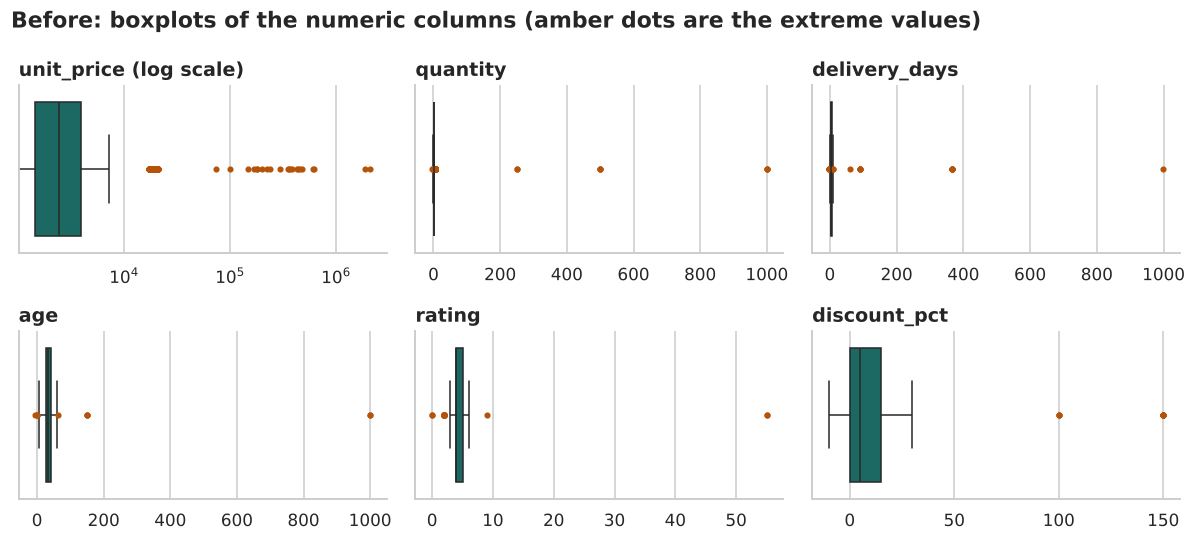

In [10]:
def box_panel(frame, title, fname):
    cols = ["unit_price", "quantity", "delivery_days", "age", "rating", "discount_pct"]
    fig, axes = plt.subplots(2, 3, figsize=(11, 5))
    for ax, c in zip(axes.ravel(), cols):
        sns.boxplot(x=frame[c].dropna(), ax=ax, color=TEAL, fliersize=3, flierprops={"markerfacecolor": AMBER, "markeredgecolor": AMBER})
        ax.set_title(c); ax.set_xlabel("")
        if c == "unit_price":
            ax.set_xscale("log"); ax.set_title("unit_price (log scale)")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); save(fig, fname); plt.show()

box_panel(df, "Before: boxplots of the numeric columns (amber dots are the extreme values)", "02_outliers_before.png")

### Which detection method?
Three common ways, and what each is good at:

| Method | Rule | Weakness |
|---|---|---|
| **IQR fence** | outside Q1 − 1.5·IQR … Q3 + 1.5·IQR | flags real but rare values |
| **Z-score** | more than 3 standard deviations from the mean | the outliers themselves inflate the mean and spread, hiding each other |
| **Domain rule** | outside a range that makes sense for the business | needs someone who knows the business |

Let's compare them on the same columns.

In [11]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); spread = q3 - q1
    return q1 - k * spread, q3 + k * spread

# Business rules: what a real order can look like
RULES = {"quantity": (1, 10), "age": (18, 80), "rating": (1, 5), "delivery_days": (1, 30), "discount_pct": (0, 90)}

rows = []
for col, (lo, hi) in RULES.items():
    s = df[col].dropna()
    l, h = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({"column": col, "IQR flags": int(((s < l) | (s > h)).sum()), "z>3 flags": int((z.abs() > 3).sum()),
                 "rule range": f"{lo} to {hi}", "rule flags": int((~s.between(lo, hi)).sum())})
display(pd.DataFrame(rows).set_index("column"))

,IQR flags,z>3 flags,rule range,rule flags
column,,,,
quantity,264,8,1 to 10,31
age,11,5,18 to 80,11
rating,34,2,1 to 5,8
delivery_days,18,10,1 to 30,16
discount_pct,10,10,0 to 90,13


Notice `quantity`: the IQR fence flags 264 rows, basically every order of four or more items, even though those are perfectly normal. The z-score catches only 8, because the absurd quantities (250, 500, 999) inflate the standard deviation and hide the smaller mistakes (0 and negatives). The domain rule flags 31, exactly the impossible ones. **For columns with a natural valid range, the domain rule is the better tool.**

`unit_price` is harder, because a tablet really does cost 10× a book. Watch what a global IQR fence does:

In [12]:
valid_price = df["unit_price"].where(df["unit_price"] > 0)
low, high = iqr_bounds(valid_price.dropna())
flagged = valid_price > high
print(f"Global IQR fence flags {int(flagged.sum())} prices above {high:,.0f}. Which products are they?")
display(df.loc[flagged, "product"].value_counts().head(8).to_frame("flagged rows"))

Global IQR fence flags 135 prices above 7,613. Which products are they?


,flagged rows
product,
Tablet,115
Bedsheet Set,3
Cookware Set,3
Mixer Grinder,2
Backpack,2
Running Shoes,2
Perfume,2
Cookbook,1


The list is dominated by Tablet, a legitimately expensive product, with a handful of real typos hiding among the rest. The fix is to compare each price with **its own product's typical price**: a Tablet at ₹19,000 is normal, a Tablet at ₹1,900,000 is not.

In [13]:
# 1) Impossible values -> NaN (treated as missing; Step 8 decides how to fill them)
for col, (lo, hi) in RULES.items():
    bad = df[col].notna() & ~df[col].between(lo, hi)
    log("7 Outliers", f"{col} outside {lo}-{hi}", "Set to NaN", bad.sum())
    print(f"{col:14s} {int(bad.sum()):>3} impossible values  -> NaN")
    df.loc[bad, col] = np.nan

# 2) Prices: non-positive, then far from the product's own median
neg = df["unit_price"] <= 0
log("7 Outliers", "unit_price zero or negative", "Set to NaN", neg.sum())
df.loc[neg, "unit_price"] = np.nan

ratio = df["unit_price"] / df.groupby("product")["unit_price"].transform("median")
bad_price = ratio.notna() & ((ratio > 3) | (ratio < 1 / 3))
log("7 Outliers", "unit_price more than 3x away from its product's median (extra zeros)", "Set to NaN", bad_price.sum())
print(f"{'unit_price':14s} {int(neg.sum()):>3} non-positive, {int(bad_price.sum())} far from product median -> NaN")
df.loc[bad_price, "unit_price"] = np.nan

# 3) Emails that cannot be emails
EMAIL_RE = r"^[\w.+-]+@[\w-]+\.[\w.-]+$"
bad_email = df["email"].notna() & ~df["email"].str.match(EMAIL_RE, na=False)
log("7 Outliers", "email not in name@domain.tld form", "Set to NaN", bad_email.sum())
print(f"{'email':14s} {int(bad_email.sum()):>3} malformed -> NaN")
df.loc[bad_email, "email"] = np.nan

quantity        31 impossible values  -> NaN
age             11 impossible values  -> NaN
rating           8 impossible values  -> NaN
delivery_days   16 impossible values  -> NaN
discount_pct    13 impossible values  -> NaN
unit_price       7 non-positive, 22 far from product median -> NaN
email           40 malformed -> NaN


## Step 8. Missing values: one strategy per column
Beginners often write `df.fillna(df.mean())` and move on. That is rarely right. Ask for each column: *can I recover the true value, can I make a defensible estimate, or is it better to leave the gap?*

Where we stand now (the NaNs from Step 3 plus everything we invalidated in Step 7):

In [14]:
now = df.isna().sum()
display(now[now > 0].sort_values(ascending=False).to_frame("missing").assign(pct=lambda d: (d["missing"] / len(df) * 100).round(1)))

,missing,pct
rating,307,13.3
discount_pct,243,10.6
age,195,8.5
email,178,7.7
delivery_days,131,5.7
payment_method,92,4.0
customer_name,69,3.0
unit_price,63,2.7
city,46,2.0
category,34,1.5


In [15]:
strategy = pd.DataFrame([
    ["order_date",     "Drop the row",                       "An order we cannot place in time is useless for trends"],
    ["customer_name, email, age", "Recover from the customer's other orders", "The same customer_id appears many times with the same details"],
    ["category",       "Recover from the product",           "Each product belongs to exactly one category"],
    ["unit_price",     "Median price of that product",       "Prices vary only about ±10% per product; flagged in price_imputed"],
    ["delivery_days",  "Median of that city",                "Delivery time depends on the city; flagged in delivery_imputed"],
    ["quantity",       "Most common value (1)",              "Most orders are a single item"],
    ["discount_pct",   "0 (no discount)",                    "Assumption: a blank discount means none. Confirm with the business"],
    ["city, payment_method, status", "Label 'Unknown'",      "Cannot be inferred; keep the rows, keep the honesty"],
    ["rating",         "Leave as NaN",                       "Ratings are opinions. Inventing them would bias every rating analysis"],
], columns=["column", "strategy", "why"])
display(strategy.style.hide(axis="index"))

column,strategy,why
order_date,Drop the row,An order we cannot place in time is useless for trends
"customer_name, email, age",Recover from the customer's other orders,The same customer_id appears many times with the same details
category,Recover from the product,Each product belongs to exactly one category
unit_price,Median price of that product,Prices vary only about ±10% per product; flagged in price_imputed
delivery_days,Median of that city,Delivery time depends on the city; flagged in delivery_imputed
quantity,Most common value (1),Most orders are a single item
discount_pct,0 (no discount),Assumption: a blank discount means none. Confirm with the business
"city, payment_method, status",Label 'Unknown',"Cannot be inferred; keep the rows, keep the honesty"
rating,Leave as NaN,Ratings are opinions. Inventing them would bias every rating analysis


In [16]:
# order_date: drop
no_date = df["order_date"].isna()
log("8 Missing", "order_date missing or not a real date", "Dropped the rows", no_date.sum())
df = df[~no_date].reset_index(drop=True)

# name, email, age: recover from the same customer's other orders ('first' skips NaN)
for col in ["customer_name", "email", "age"]:
    from_customer = df.groupby("customer_id")[col].transform("first")
    recovered = int((df[col].isna() & from_customer.notna()).sum())
    df[col] = df[col].fillna(from_customer)
    log("8 Missing", f"{col} missing", "Recovered from the customer's other orders", recovered)
    print(f"{col:14s} recovered {recovered:>3} from other orders by the same customer")

# category: recover from product
prod_cat = df.dropna(subset=["category"]).groupby("product")["category"].agg(lambda s: s.mode().iat[0])
m = df["category"].isna()
df.loc[m, "category"] = df.loc[m, "product"].map(prod_cat)
log("8 Missing", "category missing", "Looked up from the product", m.sum())

# unit_price: product median (flag it)
df["price_imputed"] = df["unit_price"].isna()
df["unit_price"] = df["unit_price"].fillna(df.groupby("product")["unit_price"].transform("median"))
log("8 Missing", "unit_price missing or invalid", "Filled with the product's median price", df["price_imputed"].sum())

# labels that cannot be inferred
for col in ["city", "payment_method", "status"]:
    n = int(df[col].isna().sum()); df[col] = df[col].fillna("Unknown")
    log("8 Missing", f"{col} missing", "Labelled 'Unknown'", n)

# delivery_days: median of the city (flag it), then overall median as a fallback
df["delivery_imputed"] = df["delivery_days"].isna()
df["delivery_days"] = df["delivery_days"].fillna(df.groupby("city")["delivery_days"].transform("median"))
df["delivery_days"] = df["delivery_days"].fillna(df["delivery_days"].median()).round()
log("8 Missing", "delivery_days missing or invalid", "Filled with the city's median", df["delivery_imputed"].sum())

# quantity, discount, remaining ages
n = int(df["quantity"].isna().sum()); df["quantity"] = df["quantity"].fillna(df["quantity"].mode().iat[0])
log("8 Missing", "quantity missing or invalid", "Filled with the most common value", n)
n = int(df["discount_pct"].isna().sum()); df["discount_pct"] = df["discount_pct"].fillna(0)
log("8 Missing", "discount_pct missing or invalid", "Assumed no discount (0)", n)
df["age_imputed"] = df["age"].isna()
n = int(df["age_imputed"].sum()); df["age"] = df["age"].fillna(df["age"].median()).round()
log("8 Missing", "age still missing after customer lookup", "Filled with the median age", n)

left = df.isna().sum(); left = left[left > 0]
print("\nStill missing on purpose:", left.to_dict())

customer_name  recovered  61 from other orders by the same customer
email          recovered 158 from other orders by the same customer
age            recovered 174 from other orders by the same customer

Still missing on purpose: {'customer_name': 8, 'email': 20, 'rating': 306}


## Step 9. Prove it: validation checks
Cleaning is not finished until the data passes explicit tests. If someone changes the cleaning code or feeds in next month's file, these assertions fail loudly instead of letting bad data through.

In [17]:
df["quantity"] = df["quantity"].astype(int)
df["gross"] = df["quantity"] * df["unit_price"]
df["revenue"] = (df["gross"] * (1 - df["discount_pct"] / 100)).round(2)
df["month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

checks = {
    "order_id is unique":                       df["order_id"].is_unique,
    "no missing order_date":                    df["order_date"].notna().all(),
    "dates fall in 2025-01-01 .. 2026-09-30":   df["order_date"].between("2025-01-01", "2026-09-30").all(),
    "6 categories only":                        set(df["category"]) == {"Electronics", "Fashion", "Home & Kitchen", "Beauty", "Books", "Sports"},
    "status is one of the 5 known values":      set(df["status"]) <= {"Delivered", "Returned", "Cancelled", "Pending", "Unknown"},
    "quantity between 1 and 10":                df["quantity"].between(1, 10).all(),
    "unit_price positive":                      (df["unit_price"] > 0).all(),
    "age between 18 and 80":                    df["age"].between(18, 80).all(),
    "rating between 1 and 5 (where present)":   df["rating"].dropna().between(1, 5).all(),
    "delivery_days between 1 and 30":           df["delivery_days"].between(1, 30).all(),
    "discount between 0 and 90":                df["discount_pct"].between(0, 90).all(),
    "revenue never negative":                   (df["revenue"] >= 0).all(),
    "no NaN left outside name, email, rating":  df.drop(columns=["customer_name", "email", "rating"]).isna().sum().sum() == 0,
}
for name, ok_ in checks.items():
    print(("PASS" if ok_ else "FAIL"), "-", name)
assert all(checks.values()), "A validation check failed"
print(f"\nAll {len(checks)} checks passed on {len(df):,} rows.")

PASS - order_id is unique
PASS - no missing order_date
PASS - dates fall in 2025-01-01 .. 2026-09-30
PASS - 6 categories only
PASS - status is one of the 5 known values
PASS - quantity between 1 and 10
PASS - unit_price positive
PASS - age between 18 and 80
PASS - rating between 1 and 5 (where present)
PASS - delivery_days between 1 and 30
PASS - discount between 0 and 90
PASS - revenue never negative
PASS - no NaN left outside name, email, rating

All 13 checks passed on 2,291 rows.


## Step 10. Before and after
A cleaning job is easy to claim and hard to believe. Put the evidence side by side.

In [18]:
num = lambda c: pd.to_numeric(raw[c].str.replace(r"₹|Rs\.?|,|\s", "", regex=True), errors="coerce")
summary = pd.DataFrame([
    ["Rows", len(raw), len(df)],
    ["Duplicate rows", int(raw.duplicated().sum()), int(df.duplicated().sum())],
    ["Placeholder / missing cells (original columns)", cells_before, int(df[raw.columns].isna().sum().sum())],
    ["Distinct category spellings", raw["category"].nunique(), df["category"].nunique()],
    ["Distinct city spellings", raw["city"].nunique(), df["city"].nunique()],
    ["Distinct payment spellings", raw["payment_method"].nunique(), df["payment_method"].nunique()],
    ["Highest delivery_days", num("delivery_days").max(), df["delivery_days"].max()],
    ["Highest age", num("age").max(), df["age"].max()],
    ["Highest rating", num("rating").max(), df["rating"].max()],
    ["Lowest quantity", num("quantity").min(), df["quantity"].min()],
    ["Largest single unit_price", num("unit_price").max(), df["unit_price"].max()],
], columns=["Measure", "Before", "After"])
display(summary.style.hide(axis="index").format({"Before": "{:,.0f}", "After": "{:,.0f}"}))

Measure,Before,After
Rows,"2,435","2,291"
Duplicate rows,80,0
Placeholder / missing cells (original columns),"1,321",334
Distinct category spellings,42,6
Distinct city spellings,57,9
Distinct payment spellings,35,6
Highest delivery_days,999,9
Highest age,999,64
Highest rating,55,5
Lowest quantity,-4,1


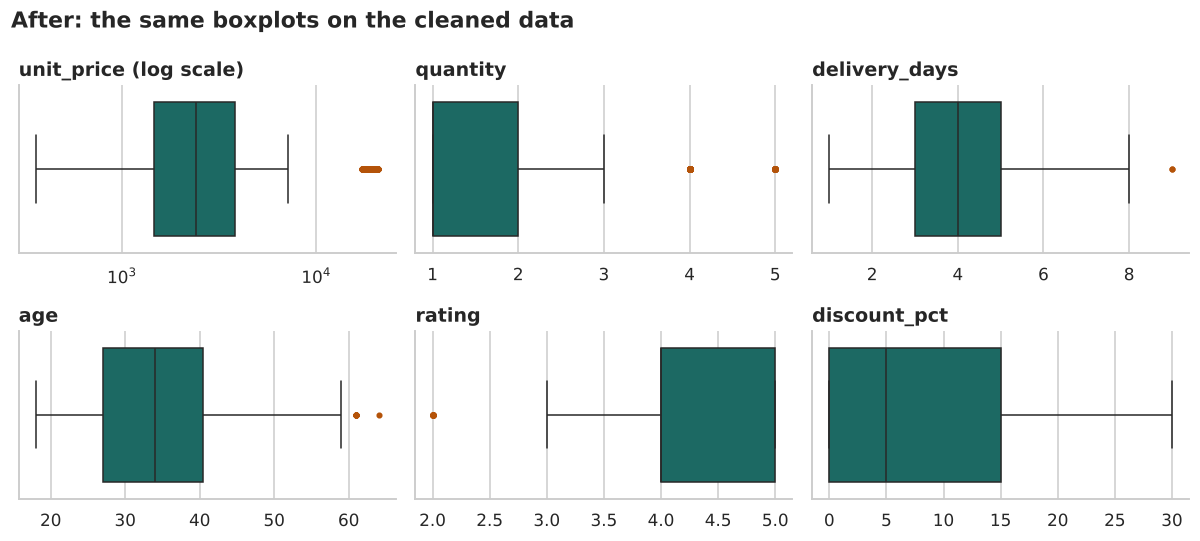

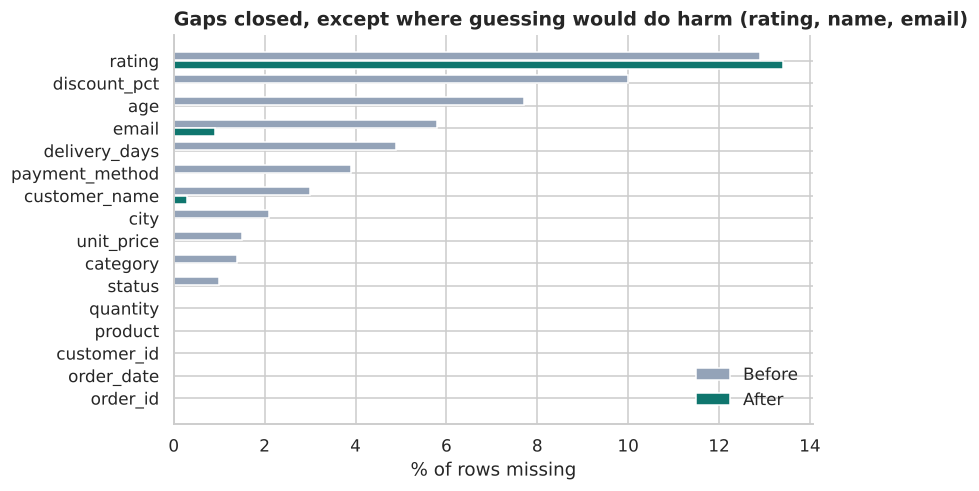

In [19]:
box_panel(df, "After: the same boxplots on the cleaned data", "03_outliers_after.png")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
cmp = pd.DataFrame({"Before": audit["pct"], "After": (df[raw.columns].isna().mean() * 100).round(1)}).sort_values("Before")
y = np.arange(len(cmp))
ax.barh(y + 0.19, cmp["Before"], height=0.36, color=GREY, label="Before")
ax.barh(y - 0.19, cmp["After"], height=0.36, color=TEAL, label="After")
ax.set_yticks(y); ax.set_yticklabels(cmp.index)
ax.set_xlabel("% of rows missing"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Gaps closed, except where guessing would do harm (rating, name, email)")
save(fig, "04_missing_before_after.png"); plt.show()

## Step 11. Tell the story
Clean data is the means, not the goal. Each chart below answers one business question, and **its title states the finding** rather than just naming the axes. Someone skimming only the titles should still get the message.

Revenue here means *delivered* orders only (returned, cancelled and pending orders have not earned anything yet).

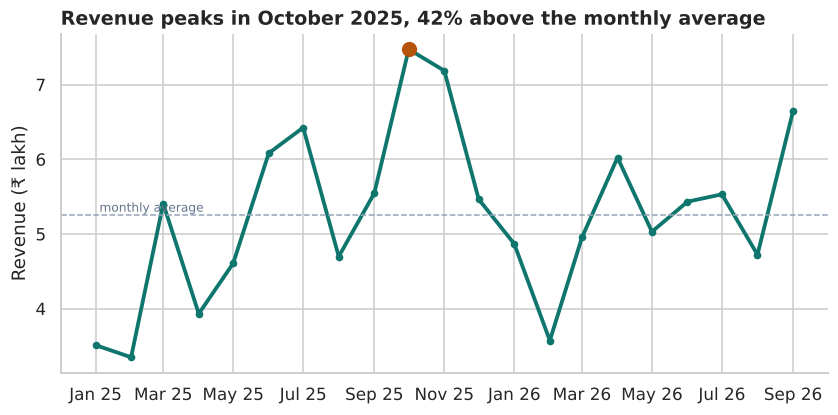

In [20]:
STORY = []   # (file name, headline) for the report
def story(fig, ax, name, headline):
    ax.set_title(headline); save(fig, name); STORY.append((name, headline)); plt.show()

ok = df[df["status"] == "Delivered"]
monthly = ok.groupby("month")["revenue"].sum()
peak = monthly.idxmax()
above_avg = (monthly.max() / monthly.mean() - 1) * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values / 1e5, color=TEAL, lw=2.5, marker="o", ms=4)
ax.scatter([peak], [monthly.max() / 1e5], color=AMBER, s=80, zorder=5)
ax.axhline(monthly.mean() / 1e5, color=GREY, ls="--", lw=1)
ax.text(monthly.index[0], monthly.mean() / 1e5, " monthly average", va="bottom", color="#64748b", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax.set_ylabel("Revenue (₹ lakh)")
story(fig, ax, "05_revenue_trend.png", f"Revenue peaks in {peak:%B %Y}, {above_avg:.0f}% above the monthly average")

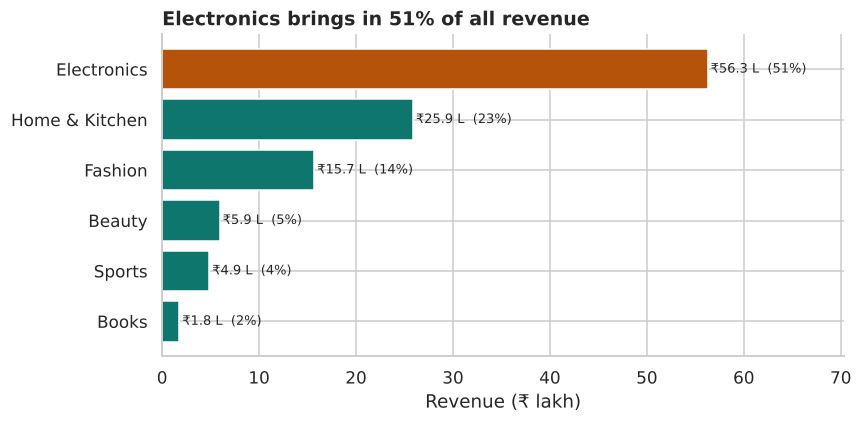

In [21]:
by_cat = ok.groupby("category")["revenue"].sum().sort_values()
top_cat, top_share = by_cat.index[-1], by_cat.iloc[-1] / by_cat.sum() * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(by_cat.index, by_cat.values / 1e5, color=[AMBER if c == top_cat else TEAL for c in by_cat.index])
for yy, v in enumerate(by_cat.values):
    ax.text(v / 1e5 + 0.3, yy, f"₹{v/1e5:,.1f} L  ({v/by_cat.sum()*100:.0f}%)", va="center", fontsize=8.5)
ax.set_xlabel("Revenue (₹ lakh)"); ax.set_xlim(0, by_cat.max() / 1e5 * 1.25)
story(fig, ax, "06_revenue_by_category.png", f"{top_cat} brings in {top_share:.0f}% of all revenue")

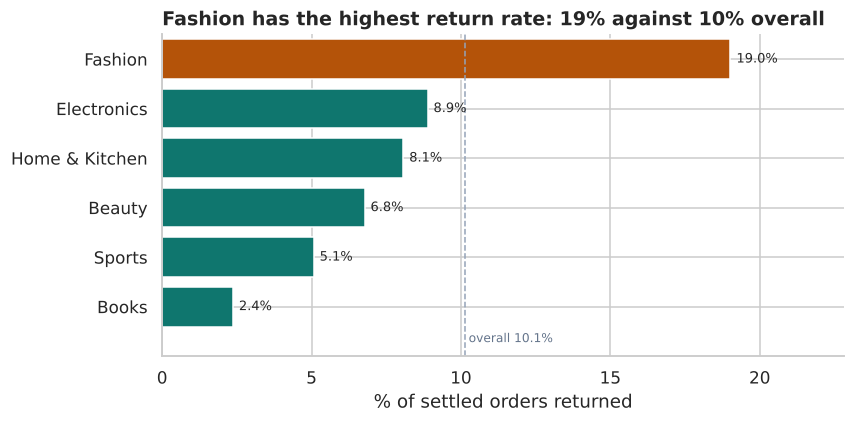

In [22]:
settled = df[df["status"].isin(["Delivered", "Returned"])]
ret = settled.groupby("category")["status"].apply(lambda s: (s == "Returned").mean() * 100).sort_values()
overall_ret = (settled["status"] == "Returned").mean() * 100
worst_cat = ret.index[-1]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(ret.index, ret.values, color=[AMBER if c == worst_cat else TEAL for c in ret.index])
ax.axvline(overall_ret, color=GREY, ls="--", lw=1)
ax.text(overall_ret, -0.65, f" overall {overall_ret:.1f}%", color="#64748b", fontsize=8, va="center")
for yy, v in enumerate(ret.values):
    ax.text(v + 0.2, yy, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% of settled orders returned"); ax.set_xlim(0, ret.max() * 1.2); ax.set_ylim(-1, len(ret) - 0.5)
story(fig, ax, "07_return_rate.png", f"{worst_cat} has the highest return rate: {ret.max():.0f}% against {overall_ret:.0f}% overall")

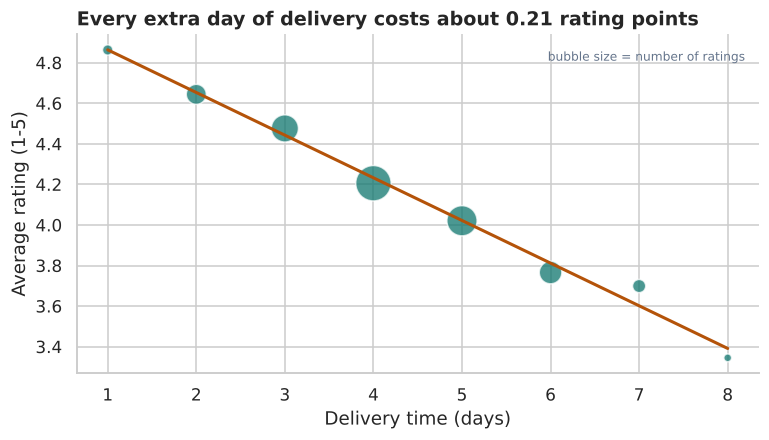

In [23]:
rated = df.dropna(subset=["rating"])
by_days = rated.groupby("delivery_days")["rating"].agg(["mean", "count"]).query("count >= 15")
slope, intercept = np.polyfit(by_days.index.astype(float), by_days["mean"], 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(by_days.index, by_days["mean"], s=by_days["count"] * 0.9, color=TEAL, alpha=0.75, edgecolor="white")
xs = np.array([by_days.index.min(), by_days.index.max()], dtype=float)
ax.plot(xs, slope * xs + intercept, color=AMBER, lw=2)
ax.set_xlabel("Delivery time (days)"); ax.set_ylabel("Average rating (1-5)")
ax.text(0.98, 0.95, "bubble size = number of ratings", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#64748b")
story(fig, ax, "08_delivery_vs_rating.png", f"Every extra day of delivery costs about {abs(slope):.2f} rating points")

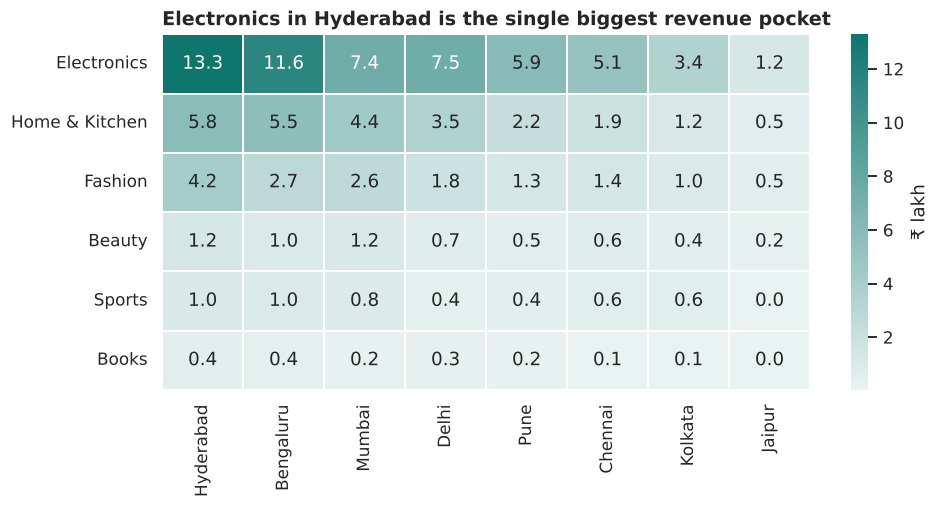

In [24]:
known = ok[ok["city"] != "Unknown"]
grid = known.pivot_table(index="category", columns="city", values="revenue", aggfunc="sum").fillna(0) / 1e5
grid = grid[grid.sum().sort_values(ascending=False).index]
grid = grid.loc[grid.sum(axis=1).sort_values(ascending=False).index]
best_cat, best_city = grid.stack().idxmax()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
sns.heatmap(grid, annot=True, fmt=".1f", cmap=sns.light_palette(TEAL, as_cmap=True), linewidths=1, linecolor="white",
            cbar_kws={"label": "₹ lakh"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
story(fig, ax, "09_category_by_city.png", f"{best_cat} in {best_city} is the single biggest revenue pocket")

### Key findings
The sentences below are generated from the data, so they stay correct if the file changes.

In [25]:
y25 = ok[ok["order_date"].dt.year == 2025]
festive = y25[y25["order_date"].dt.month.isin([10, 11])]["revenue"].sum() / y25["revenue"].sum() * 100
slow = df[df["city"] != "Unknown"].groupby("city").agg(days=("delivery_days", "mean"), rating=("rating", "mean"))
slowest, fastest = slow["days"].idxmax(), slow["days"].idxmin()
pay = df[df["payment_method"] != "Unknown"]["payment_method"].value_counts(normalize=True) * 100
cust = ok.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)
top10 = cust.head(max(1, int(len(cust) * 0.1))).sum() / cust.sum() * 100

FINDINGS = [
    f"October and November produced {festive:.0f}% of 2025 revenue. Stock, staffing and ad budget should be planned around that window.",
    f"{top_cat} is the revenue engine ({top_share:.0f}%), but {worst_cat} has the highest returns ({ret.max():.0f}%), which erodes what it earns.",
    f"Slower delivery means unhappier customers: ratings fall by about {abs(slope):.2f} points for each extra day.",
    f"{slowest} is the slowest city ({slow.loc[slowest, 'days']:.1f} days, average rating {slow.loc[slowest, 'rating']:.2f}) and {fastest} the fastest ({slow.loc[fastest, 'days']:.1f} days, {slow.loc[fastest, 'rating']:.2f}).",
    f"{pay.index[0]} is the most used payment method ({pay.iloc[0]:.0f}% of orders with a known method), so a failure there would hit the largest share of checkouts.",
    f"The top 10% of customers generate {top10:.0f}% of revenue, which makes retention worth more than acquisition.",
]
for i, f in enumerate(FINDINGS, 1):
    print(f"{i}. {f}")

1. October and November produced 23% of 2025 revenue. Stock, staffing and ad budget should be planned around that window.
2. Electronics is the revenue engine (51%), but Fashion has the highest returns (19%), which erodes what it earns.
3. Slower delivery means unhappier customers: ratings fall by about 0.21 points for each extra day.
4. Jaipur is the slowest city (6.2 days, average rating 3.79) and Delhi the fastest (3.9 days, 4.23).
5. UPI is the most used payment method (44% of orders with a known method), so a failure there would hit the largest share of checkouts.
6. The top 10% of customers generate 37% of revenue, which makes retention worth more than acquisition.


## Step 12. Save the cleaned data and publish a report
The cleaned file feeds any later analysis. The HTML report is for people who will never open this notebook: headline numbers, the findings, the charts, and the full cleaning log. It is a single file with the charts embedded, so you can email it as is.

In [26]:
df.to_csv(DATA / "clean_orders.csv", index=False)
log_df = pd.DataFrame(LOG)
log_df.to_csv(REPORT / "cleaning_log.csv", index=False)

def b64(name):
    return base64.b64encode((FIG / name).read_bytes()).decode()

kpis = [("Rows in", f"{len(raw):,}"), ("Rows out", f"{len(df):,}"),
        ("Duplicates removed", f"{int(log_df[log_df.step == '6 Duplicates'].affected.sum())}"),
        ("Impossible values fixed", f"{int(log_df[log_df.step == '7 Outliers'].affected.sum())}"),
        ("Delivered revenue", f"₹{ok['revenue'].sum()/1e7:.2f} Cr")]
kpi_html = "".join(f'<div class="k"><b>{v}</b><span>{html.escape(k)}</span></div>' for k, v in kpis)
find_html = "".join(f"<li>{html.escape(f)}</li>" for f in FINDINGS)
fig_html = "".join(f'<figure><img alt="{html.escape(t)}" src="data:image/png;base64,{b64(n)}"><figcaption>{html.escape(t)}</figcaption></figure>' for n, t in STORY)
ba_html = "".join(f'<figure><img alt="{html.escape(t)}" src="data:image/png;base64,{b64(n)}"><figcaption>{html.escape(t)}</figcaption></figure>'
                  for n, t in [("02_outliers_before.png", "Outliers before cleaning"), ("03_outliers_after.png", "Outliers after cleaning"),
                               ("04_missing_before_after.png", "Missing values before and after")])
log_html = log_df.rename(columns={"step": "Step", "issue": "Issue", "action": "Action", "affected": "Affected", "unit": "Unit"}).to_html(index=False, border=0)

TEMPLATE = """<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Orders data: cleaning and findings</title>
<style>
body{font:15px/1.55 system-ui,Segoe UI,Roboto,sans-serif;color:#14201e;background:#f3f5f4;margin:0;padding:24px 16px}
main{max-width:980px;margin:auto}h1{font-size:28px;margin:0 0 4px}h2{margin:36px 0 10px;font-size:20px}
.sub{color:#5d6b68;margin:0 0 20px}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(150px,1fr));gap:10px}
.k{background:#fff;border:1px solid #dbe2df;border-radius:10px;padding:12px 14px}.k b{display:block;font-size:24px;color:#0f766e}.k span{color:#5d6b68;font-size:12.5px}
ol.f{padding-left:20px}ol.f li{margin:8px 0}
figure{margin:14px 0;background:#fff;border:1px solid #dbe2df;border-radius:10px;padding:12px}figure img{max-width:100%;height:auto;display:block}
figcaption{color:#5d6b68;font-size:13px;margin-top:6px}
.tw{overflow-x:auto;background:#fff;border:1px solid #dbe2df;border-radius:10px}
table{border-collapse:collapse;width:100%;font-size:13px}th,td{text-align:left;padding:7px 10px;border-bottom:1px solid #e8eeec;vertical-align:top}
th{color:#5d6b68;text-transform:uppercase;font-size:11px;letter-spacing:.06em}
</style></head><body><main>
<h1>Orders data: cleaning and findings</h1>
<p class="sub">E-commerce orders, Jan 2025 to Sep 2026. Raw file: %%RAW%% rows. Cleaned file: %%CLEAN%% rows.</p>
<div class="kpis">%%KPIS%%</div>
<h2>What the cleaned data says</h2><ol class="f">%%FINDINGS%%</ol>
<h2>Charts</h2>%%FIGS%%
<h2>How clean is it now?</h2>%%BA%%
<h2>Cleaning log</h2><div class="tw">%%LOG%%</div>
</main></body></html>"""
page = (TEMPLATE.replace("%%RAW%%", f"{len(raw):,}").replace("%%CLEAN%%", f"{len(df):,}").replace("%%KPIS%%", kpi_html)
        .replace("%%FINDINGS%%", find_html).replace("%%FIGS%%", fig_html).replace("%%BA%%", ba_html).replace("%%LOG%%", log_html))
(REPORT / "data_story_report.html").write_text(page, encoding="utf-8")
print("Saved:", DATA / "clean_orders.csv", "|", REPORT / "cleaning_log.csv", "|", REPORT / "data_story_report.html")
display(log_df)

Saved: /home/claude/data-cleaning-project/data/clean_orders.csv | /home/claude/data-cleaning-project/report/cleaning_log.csv | /home/claude/data-cleaning-project/report/data_story_report.html


,step,issue,action,affected,unit
0,3 Missing tokens,"Blanks, N/A, na, NULL, -, ?, None all mean 'missing'",Converted to real NaN,1321,cells
1,4 Text,category: 23 spellings of 6 real values,Mapped to one standard spelling,242,rows
2,4 Text,city: 29 spellings of 8 real values,Mapped to one standard spelling,315,rows
3,4 Text,payment_method: 18 spellings of 5 real values,Mapped to one standard spelling,171,rows
4,4 Text,status: 10 spellings of 4 real values,Mapped to one standard spelling,134,rows
5,5 Types,order_date written in 4 formats,Parsed with explicit formats,2425,rows
6,5 Types,order_date values that are not real dates,Set to NaT (handled in step 8),10,rows
7,5 Types,"unit_price stored as text like '₹1,299' or 'Rs. 1,299'","Stripped symbols, converted to number",554,rows
8,6 Duplicates,"Rows copied twice (exact, or identical once text is standardised)","Kept the first, dropped the rest",135,rows
9,7 Outliers,quantity outside 1-10,Set to NaN,31,rows


## Where to go next
1. **Change an assumption and watch the impact.** Fill `discount_pct` with the median instead of 0 and compare total revenue. How sensitive is the answer?
2. **Add a rule to the mapping** (a new city spelling in the data) and confirm the assertion in Step 4 catches it first.
3. **Wrap Steps 3 to 9 in a function** `clean_orders(raw) -> df` so next month's file takes one line.
4. **Try winsorising** (capping at the 1st and 99th percentile) on `delivery_days` instead of replacing, and compare the rating trend.
5. **Test a question the story raised:** is the return rate higher for heavily discounted orders?